Q1. equilibrium conversion checker
in a reactor the reaction A + B Gives(arrow) reaches equlibrium.Intial concentrations are [A]0 = 1.5,[B]]0 =1 and [C]0 = 0mol/L.If x mol/L of C is formed,Kc =x/((1.5 - x)(1 - x)),which rearranges to the quadratic equation
Kc*x**2 - (2.5Kc + 1)*x +1.5Kc = 0
write a python program that:
(a)reads Kc using input(),prints the data type of the raw input and of the converted value, and shoiw a clear message (no crash) if the text is not a number or if Kc<= 0;
(b)find a,b.c,the determinant and both roots;
(c)selects the physically meaningful roots(0<= x <= 1,because B is limiting);
(d)prints equilibrium [A],[B],[C](3 decimals) and the conversion of the limiting reactant B = x/[b]0*100(%);
(e)classifies the conversion using if/elif/else :>= 70% "High",>= 40% "Moderate",otherwise "Low".
Teat with Kc = 4,Kc = 0.5, Kc =abc and Kc = -2


In [2]:
import math


A0 = 1.5
B0 = 1.0
C0 = 0.0

raw_kc = input("Enter Kc: ")
print("Raw input type:", type(raw_kc))

try:
    kc = float(raw_kc)
except ValueError:
    print("Error: Kc must be a number.")
else:
    print("Converted value type:", type(kc))

    if not math.isfinite(kc) or kc <= 0:
        print("Error: Kc must be a finite number greater than 0.")
    else:
        a = kc
        b = -(2.5 * kc + 1)
        c = 1.5 * kc
        determinant = b**2 - 4 * a * c

        print(f"a = {a}, b = {b}, c = {c}")
        print("Determinant (discriminant) =", determinant)

        if determinant < 0:
            print("Error: no real roots exist.")
        else:
            root1 = (-b + math.sqrt(determinant)) / (2 * a)
            root2 = (-b - math.sqrt(determinant)) / (2 * a)
            print(f"Root 1 = {root1:.6f}")
            print(f"Root 2 = {root2:.6f}")

            physical_roots = [x for x in (root1, root2) if 0 <= x <= B0]

            if not physical_roots:
                print("No physically meaningful root is in the range 0 <= x <= 1.")
            else:
                for x in physical_roots:
                    equilibrium_A = A0 - x
                    equilibrium_B = B0 - x
                    equilibrium_C = C0 + x
                    conversion = x / B0 * 100

                    print(f"\nFor x = {x:.6f} mol/L:")
                    print(f"Equilibrium [A] = {equilibrium_A:.3f} mol/L")
                    print(f"Equilibrium [B] = {equilibrium_B:.3f} mol/L")
                    print(f"Equilibrium [C] = {equilibrium_C:.3f} mol/L")
                    print(f"Conversion of B = {conversion:.2f}%")

                    if conversion >= 70:
                        category = "High"
                    elif conversion >= 40:
                        category = "Moderate"
                    else:
                        category = "Low"

                    print("Category:", category)

Raw input type: <class 'str'>
Converted value type: <class 'float'>
a = 4.0, b = -11.0, c = 6.0
Determinant (discriminant) = 25.0
Root 1 = 2.000000
Root 2 = 0.750000

For x = 0.750000 mol/L:
Equilibrium [A] = 0.750 mol/L
Equilibrium [B] = 0.250 mol/L
Equilibrium [C] = 0.750 mol/L
Conversion of B = 75.00%
Category: High


Q2. Batch reactor simulation and batch tracking (10 marks)
Part A. Ia batch reactor,reactant A is consumed by a first- order reaction,dC/dt = -Kc. Use the Euler method:C_new = c_old.delta(t).Tke C0 = 2,5 mol/L,K = 0.04 min**-1,delta(t) = 1 min.
(1)Using a for loop,simulate 12 minutes and print a table of time(min),Concentration(mol/L) and Conversion(%).
(2)Using math.exp(),calculate the exact value C0e**(-Kt) at 12 min and print the absolute error of the euler result.
(3)Using a while loop,repeat the simultion until conversion reaches 40% or time resches 100 min.Print the time needed and the final concentration .

Part B .Distillation-column sample codes such as DIST2026X9Q3 are stored as text.Write a program that reads a code,loops through each character,and prints the number of digits and the sum of the digits.Show a message for an empty code and for a code with no digits.Show a message for an empty code and ABCDEF.


In [3]:
import math

# Part A: Euler simulation for a first-order reaction
C0 = 2.5  # mol/L; interpret 2,5 as 2.5
k = 0.04  # min^-1
dt = 1.0  # min
concentration = C0

euler_at_12 = C0
print("Time (min) | Concentration (mol/L) | Conversion (%)")
for time in range(13):
    if time > 0:
        concentration = concentration - k * concentration * dt
    conversion = (C0 - concentration) / C0 * 100
    print(f"{time:10d} | {concentration:22.4f} | {conversion:13.2f}")
    if time == 12:
        euler_at_12 = concentration

exact_at_12 = C0 * math.exp(-k * 12)
absolute_error = abs(exact_at_12 - euler_at_12)
print(f"\nExact concentration at 12 min = {exact_at_12:.4f} mol/L")
print(f"Absolute error at 12 min = {absolute_error:.6f} mol/L")

# Continue from the initial concentration until conversion reaches 40%.
time = 0
concentration = C0
conversion = 0
while conversion < 40 and time < 100:
    concentration = concentration - k * concentration * dt
    time += 1
    conversion = (C0 - concentration) / C0 * 100

print(f"\nTime to reach 40% conversion = {time} min")
print(f"Concentration at that time = {concentration:.4f} mol/L")
print(f"Conversion at that time = {conversion:.2f}%")

# Part B: count and sum the digits in a sample code
sample_code = input("Enter a distillation-column code: ").strip()

if sample_code == "":
    print("The code is empty.")
else:
    digit_count = 0
    digit_sum = 0

    for character in sample_code:
        if character in "0123456789":
            digit_count += 1
            digit_sum += int(character)

    print("Number of digits:", digit_count)
    print("Sum of digits:", digit_sum)

    if digit_count == 0:
        print("The code contains no digits.")

Time (min) | Concentration (mol/L) | Conversion (%)
         0 |                 2.5000 |          0.00
         1 |                 2.4000 |          4.00
         2 |                 2.3040 |          7.84
         3 |                 2.2118 |         11.53
         4 |                 2.1234 |         15.07
         5 |                 2.0384 |         18.46
         6 |                 1.9569 |         21.72
         7 |                 1.8786 |         24.86
         8 |                 1.8035 |         27.86
         9 |                 1.7313 |         30.75
        10 |                 1.6621 |         33.52
        11 |                 1.5956 |         36.18
        12 |                 1.5318 |         38.73

Exact concentration at 12 min = 1.5470 mol/L
Absolute error at 12 min = 0.015184 mol/L

Time to reach 40% conversion = 13 min
Concentration at that time = 1.4705 mol/L
Conversion at that time = 41.18%
Number of digits: 6
Sum of digits: 22


Q3.Solvent screening and sampling schedule(10 marks)
Part A. A laboratory has n candidate solvents and wants to test r od them together in a mixed solvent(order does not matter).Write a recursive function factorial(n) (remember that the base case for 0!) and a function combination(n,r) = n!/(r!(n - r)!) that uses it.Reject invalid input (negative,r > n).Print the number of possible mixtures for n =9,r = 3, and message for n = 6, r = 8.

Part B. During a crystallisation run,samples are taken at times = Fibonacci number*4 min.Write an iterative function fib_iter(n) that returns a list of the first n Fibonacci numbers, and a recursive function fib_rec(k) that returns the k-th Fibonacci number(F0 = 0,F1 = 1).For n = 10,check that both functions agree and print a table:Sample No. | Fibonacci tag | Sampling time(min).



In [4]:
# Part A: recursive factorial and combinations
def factorial(n):
    if n < 0:
        raise ValueError("n cannot be negative")
    if n == 0:
        return 1
    return n * factorial(n - 1)


def combination(n, r):
    if n < 0 or r < 0 or r > n:
        raise ValueError("Require n >= 0 and 0 <= r <= n")
    return factorial(n) // (factorial(r) * factorial(n - r))


print("Mixtures for n=9, r=3:", combination(9, 3))

try:
    print("Mixtures for n=6, r=8:", combination(6, 8))
except ValueError as error:
    print("Invalid combination:", error)


# Part B: iterative and recursive Fibonacci functions
def fib_iter(n):
    if n < 0:
        raise ValueError("n cannot be negative")

    numbers = []
    first, second = 0, 1
    for _ in range(n):
        numbers.append(first)
        first, second = second, first + second
    return numbers


def fib_rec(k):
    if k < 0:
        raise ValueError("k cannot be negative")
    if k == 0:
        return 0
    if k == 1:
        return 1
    return fib_rec(k - 1) + fib_rec(k - 2)


n = 10
fibonacci_numbers = fib_iter(n)
recursive_numbers = [fib_rec(k) for k in range(n)]
print("\nIterative and recursive results agree:", fibonacci_numbers == recursive_numbers)

print("Sample No. | Fibonacci tag | Sampling time (min)")
for sample_number, fibonacci_value in enumerate(fibonacci_numbers, start=1):
    fibonacci_index = sample_number - 1
    sampling_time = fibonacci_value * 4
    print(f"{sample_number:10d} | F{fibonacci_index} = {fibonacci_value:8d} | {sampling_time:18d}")

Mixtures for n=9, r=3: 84
Invalid combination: Require n >= 0 and 0 <= r <= n

Iterative and recursive results agree: True
Sample No. | Fibonacci tag | Sampling time (min)
         1 | F0 =        0 |                  0
         2 | F1 =        1 |                  4
         3 | F2 =        1 |                  4
         4 | F3 =        2 |                  8
         5 | F4 =        3 |                 12
         6 | F5 =        5 |                 20
         7 | F6 =        8 |                 32
         8 | F7 =       13 |                 52
         9 | F8 =       21 |                 84
        10 | F9 =       34 |                136


Q4.Kinetics and gas data:pandas and matplotlib (10 marks)
Consumption od a reactant was studied in a batch reactor with two feed concentrations of catalyst.The concentration(mol/L) was recorded:
Time_min = [0,10,20,30,40,50,]
Run1_mol_L(low catalyst) = [1.50,1.17,0.91,0.71,0.55,0.43]
Run2-MOL-L(high catalyst) = [1.50,0.96,0.61,0.39,0.25,0.16]
(a)Create a dataframe from this table.Save it as kinetics.csv(without the index column) and as kinetics.json.Read the csv back and print its shape and data types.
(b)Print the mean and standard deviation of Run1 and Run2,and state which run shows more variation.
(c)Plot both runs on one graph(Time on X-axis) with title,axis labels with units,legend and grid.
(d)Ethylene gas is compressed slowly in a piston-cylinder at constant temperature:
Volume_L = [1,2,3,4,5]
Pressure_bar = [ 5.03,2.52,1.65,1.26,1.01]
plot pressurevs. volume as a scatter plot.Calculate k as the mean of P*V and draw the reference curve P = k/V on the same graph.Add title,labels with units and legend.

CSV shape: (6, 3)
CSV data types:
Time_min        int64
Run1_mol_L    float64
Run2_mol_L    float64
dtype: object

Run 1 mean = 0.878, standard deviation = 0.402
Run 2 mean = 0.645, standard deviation = 0.507
Run 2 shows more variation.


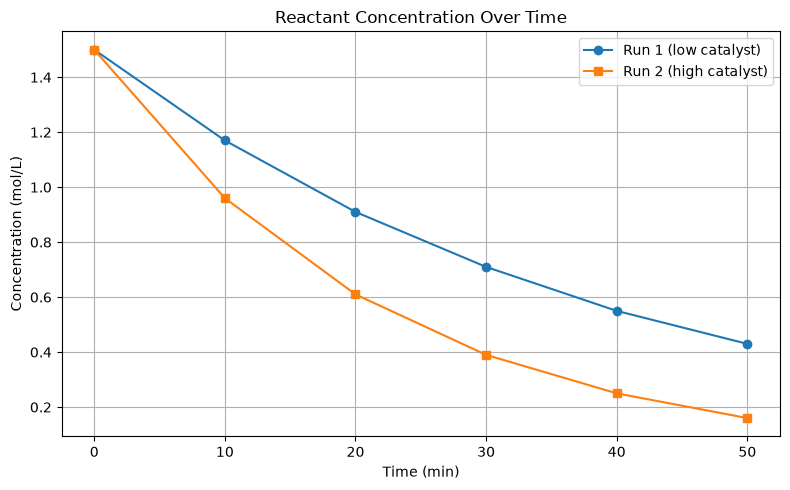


Mean P*V constant, k = 5.022 bar L


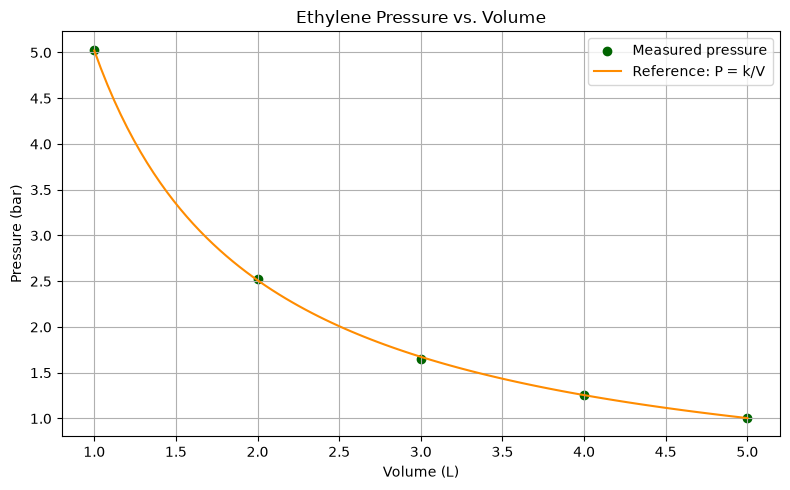

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Part A: kinetics data, file output, and statistics
time_min = [0, 10, 20, 30, 40, 50]
run1_mol_l = [1.50, 1.17, 0.91, 0.71, 0.55, 0.43]
run2_mol_l = [1.50, 0.96, 0.61, 0.39, 0.25, 0.16]

kinetics = pd.DataFrame({
    "Time_min": time_min,
    "Run1_mol_L": run1_mol_l,
    "Run2_mol_L": run2_mol_l
})

kinetics.to_csv("kinetics.csv", index=False)
kinetics.to_json("kinetics.json", orient="records", indent=4)

kinetics_from_csv = pd.read_csv("kinetics.csv")
print("CSV shape:", kinetics_from_csv.shape)
print("CSV data types:")
print(kinetics_from_csv.dtypes)

run1_mean = kinetics["Run1_mol_L"].mean()
run1_std = kinetics["Run1_mol_L"].std()
run2_mean = kinetics["Run2_mol_L"].mean()
run2_std = kinetics["Run2_mol_L"].std()

print(f"\nRun 1 mean = {run1_mean:.3f}, standard deviation = {run1_std:.3f}")
print(f"Run 2 mean = {run2_mean:.3f}, standard deviation = {run2_std:.3f}")
if run1_std > run2_std:
    print("Run 1 shows more variation.")
elif run2_std > run1_std:
    print("Run 2 shows more variation.")
else:
    print("Both runs show the same variation.")

plt.figure(figsize=(8, 5))
plt.plot(kinetics["Time_min"], kinetics["Run1_mol_L"], marker="o", label="Run 1 (low catalyst)")
plt.plot(kinetics["Time_min"], kinetics["Run2_mol_L"], marker="s", label="Run 2 (high catalyst)")
plt.title("Reactant Concentration Over Time")
plt.xlabel("Time (min)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Part B: ethylene pressure-volume data and reference curve
volume_l = np.array([1, 2, 3, 4, 5], dtype=float)
pressure_bar = np.array([5.03, 2.52, 1.65, 1.26, 1.01], dtype=float)
k_pv = np.mean(pressure_bar * volume_l)
print(f"\nMean P*V constant, k = {k_pv:.3f} bar L")

volume_curve = np.linspace(volume_l.min(), volume_l.max(), 100)
pressure_curve = k_pv / volume_curve

plt.figure(figsize=(8, 5))
plt.scatter(volume_l, pressure_bar, color="darkgreen", label="Measured pressure")
plt.plot(volume_curve, pressure_curve, color="darkorange", label="Reference: P = k/V")
plt.title("Ethylene Pressure vs. Volume")
plt.xlabel("Volume (L)")
plt.ylabel("Pressure (bar)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()